
TEST 1: NON-LINEAR DATASET
Input:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Actual: [  0 100 100   0]
Predicted: [ 33.22  33.22 100.    33.22]
Reason: XOR is non-linear and requires a hidden layer.

TEST 2: SMALL NEURAL NETWORK
Input:
 [[2 9]
 [1 5]
 [3 6]]
Actual: [92 86 89]
Predicted: [125.43  73.94  98.37]
Reason: One hidden neuron gives limited learning capacity.

TEST 3: REDUCTION IN TRAINING ERROR
Input:
 [[2 9]
 [1 5]
 [3 6]]
Actual: [92 86 89]
Predicted: [118.1   69.48  96.13]

Training Loss:
Epoch 1: 3884.744101
Epoch 10: 2870.416408
Epoch 35: 207.134312

Final Prediction: [118.1   69.48  96.13]
Final MSE: 335.140994


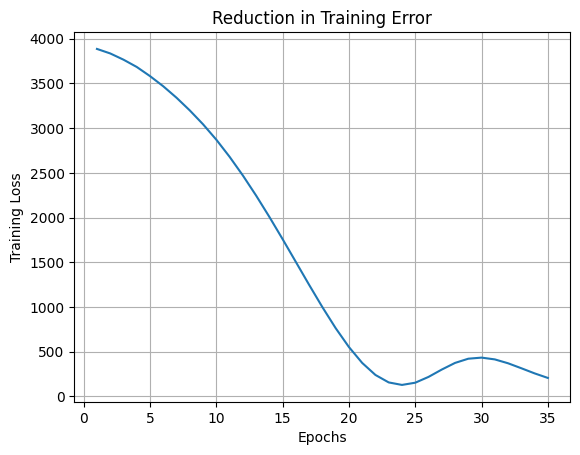

Reason: More epochs allow more weight updates through backpropagation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

def show(title, X, y, hidden=3, lr=0.1, epochs=10000):
    print(f"\n{'='*55}\n{title}\n{'='*55}")
    m = MLPRegressor(hidden_layer_sizes=(hidden,),
                     learning_rate_init=lr,
                     max_iter=epochs, random_state=42)
    m.fit(X, y)
    p = m.predict(X)
    print("Input:\n", X)
    print("Actual:", y)
    print("Predicted:", np.round(p, 2))
    return m, p


# Test 1: Non-linear XOR
X1 = np.array([[0,0],[0,1],[1,0],[1,1]])
y1 = np.array([0,100,100,0])

show("TEST 1: NON-LINEAR DATASET", X1, y1)
print("Reason: XOR is non-linear and requires a hidden layer.")


# Common dataset for Tests 2-5
X = np.array([[2,9],[1,5],[3,6]])
y = np.array([92,86,89])


# Test 2: Small neural network
show("TEST 2: SMALL NEURAL NETWORK", X, y, hidden=1)
print("Reason: One hidden neuron gives limited learning capacity.")


# Test 3: Training error
m, p = show("TEST 3: REDUCTION IN TRAINING ERROR", X, y)
loss = m.loss_curve_

print("\nTraining Loss:")
for e in [1, 10, 50, 100, 500, 1000, 5000, len(loss)]:
    if e <= len(loss):
        print(f"Epoch {e}: {loss[e-1]:.6f}")

print("\nFinal Prediction:", np.round(p, 2))
print("Final MSE:", round(mean_squared_error(y, p), 6))

plt.plot(range(1, len(loss)+1), loss)
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Reduction in Training Error")
plt.grid()
plt.show()

print("Reason: More epochs allow more weight updates through backpropagation.")